# 06 · TF-IDF baseline

The simplest trainable model: count which words and word pairs a text uses (TF-IDF) and let a logistic regression learn which ones point to which class. It runs on a normal laptop CPU in a few minutes, and every other model has to beat it.

## Settings and data

In [1]:
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_from_disk
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

# This notebook sits in <repo>/06_tfidf-baseline/, so the repo root is one level up
REPO_ROOT = Path.cwd().parent
DATASET_DIR = REPO_ROOT / "data" / "hf-dataset"
RESULTS_DIR = Path("results")
MODEL_DIR = REPO_ROOT / "models" / "tfidf-logreg"   # ignored by git (too big)

# Same order as the dataset (step 04)
LABEL_NAMES = ["Human", "AI-generated", "AI-assisted"]

# Settings tried on the validation set; the best one is used for the test set
NGRAM_RANGES = [(1, 1), (1, 2)]
C_VALUES = [1, 3, 10, 30]
MIN_DF = 5
MAX_FEATURES = 200_000

RESULTS_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

dataset = load_from_disk(str(DATASET_DIR))
X_train, y_train = dataset["train"]["text"], np.array(dataset["train"]["label"])
X_val, y_val = dataset["validation"]["text"], np.array(dataset["validation"]["label"])
X_test, y_test = dataset["test"]["text"], np.array(dataset["test"]["label"])
print(f"train {len(X_train):,} | validation {len(X_val):,} | test {len(X_test):,}")

train 24,986 | validation 2,906 | test 2,737


## Tune on the validation set

Two feature settings (single words, or words plus word pairs) and four regularisation strengths. The test set isn't touched here.

In [2]:
# The TF-IDF features are built once per n-gram setting and reused for every C,
# which makes the search much faster than a full grid search.
runs = []
for ngram_range in NGRAM_RANGES:
    start = time.time()
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, min_df=MIN_DF, max_df=0.98,
                                 max_features=MAX_FEATURES, sublinear_tf=True, dtype=np.float32)
    train_features = vectorizer.fit_transform(X_train)
    val_features = vectorizer.transform(X_val)
    print(f"n-grams {ngram_range}: {train_features.shape[1]:,} features ({time.time() - start:.0f}s)")

    for C in C_VALUES:
        start = time.time()
        model = LogisticRegression(C=C, max_iter=2000, random_state=42)
        model.fit(train_features, y_train)
        val_accuracy = accuracy_score(y_val, model.predict(val_features))
        runs.append({"ngram_range": str(ngram_range), "C": C, "val_accuracy": val_accuracy,
                     "seconds": round(time.time() - start)})
        print(f"   C={C:<3} validation accuracy {val_accuracy:.2%}  ({runs[-1]['seconds']}s)")

runs = pd.DataFrame(runs).sort_values("val_accuracy", ascending=False)
runs.to_csv(RESULTS_DIR / "tfidf-tuning.csv", index=False)
best = runs.iloc[0]
print(f"\nBest: n-grams {best['ngram_range']}, C={best['C']} → {best['val_accuracy']:.2%}")

n-grams (1, 1): 69,876 features (39s)
   C=1   validation accuracy 90.36%  (16s)
   C=3   validation accuracy 91.05%  (21s)
   C=10  validation accuracy 91.16%  (20s)
   C=30  validation accuracy 91.16%  (22s)
n-grams (1, 2): 200,000 features (80s)
   C=1   validation accuracy 91.02%  (23s)
   C=3   validation accuracy 91.33%  (21s)
   C=10  validation accuracy 91.47%  (40s)
   C=30  validation accuracy 91.71%  (61s)

Best: n-grams (1, 2), C=30 → 91.71%


## Train the best setting

In [3]:
# Train the best setting once more and save it
best_ngram = tuple(int(n) for n in best["ngram_range"].strip("()").split(","))
vectorizer = TfidfVectorizer(ngram_range=best_ngram, min_df=MIN_DF, max_df=0.98,
                             max_features=MAX_FEATURES, sublinear_tf=True, dtype=np.float32)
model = LogisticRegression(C=float(best["C"]), max_iter=2000, random_state=42)
model.fit(vectorizer.fit_transform(X_train), y_train)

joblib.dump({"vectorizer": vectorizer, "model": model, "labels": LABEL_NAMES},
            MODEL_DIR / "tfidf-logreg.joblib", compress=3)
print("Saved model to", (MODEL_DIR / "tfidf-logreg.joblib").relative_to(REPO_ROOT))

Saved model to models\tfidf-logreg\tfidf-logreg.joblib


## Results

In [4]:
test_probs = model.predict_proba(vectorizer.transform(X_test))
test_pred = test_probs.argmax(axis=1)
val_pred = model.predict(vectorizer.transform(X_val))
train_pred = model.predict(vectorizer.transform(X_train))

print(f"Train accuracy:      {accuracy_score(y_train, train_pred):.2%}")
print(f"Validation accuracy: {accuracy_score(y_val, val_pred):.2%}")
print(f"Test accuracy:       {accuracy_score(y_test, test_pred):.2%}")
print(f"Test macro-F1:       {f1_score(y_test, test_pred, average='macro'):.2%}\n")
print(classification_report(y_test, test_pred, labels=[0, 1, 2], target_names=LABEL_NAMES, digits=4))

for label, name in enumerate(LABEL_NAMES):
    part = test_pred[y_test == label]
    print(f"{name:13} error: {(part != label).mean():.2%}  (n={len(part)})")

# Plain "human or AI?": both AI classes count as AI
is_ai_true, is_ai_pred = y_test > 0, test_pred > 0
print(f"\nHuman vs. AI accuracy: {(is_ai_true == is_ai_pred).mean():.2%}")
print(f"Human texts flagged as AI or AI-assisted: {is_ai_pred[~is_ai_true].mean():.2%}")

# Save test predictions (IDs only, no texts) for the model comparison later
pd.DataFrame({
    "id": dataset["test"]["id"], "true_label": y_test, "predicted_label": test_pred,
    "human_probability": test_probs[:, 0], "ai_generated_probability": test_probs[:, 1],
    "ai_assisted_probability": test_probs[:, 2], "word_count": dataset["test"]["word_count"],
}).to_csv(RESULTS_DIR / "tfidf-test-predictions.csv", index=False)

Train accuracy:      99.98%
Validation accuracy: 91.71%
Test accuracy:       91.60%
Test macro-F1:       91.59%

              precision    recall  f1-score   support

       Human     0.8884    0.9147    0.9013       914
AI-generated     0.9671    0.9671    0.9671       912
 AI-assisted     0.8925    0.8661    0.8791       911

    accuracy                         0.9160      2737
   macro avg     0.9160    0.9159    0.9159      2737
weighted avg     0.9160    0.9160    0.9159      2737

Human         error: 8.53%  (n=914)
AI-generated  error: 3.29%  (n=912)
AI-assisted   error: 13.39%  (n=911)

Human vs. AI accuracy: 93.31%
Human texts flagged as AI or AI-assisted: 8.53%


## Confusion matrix

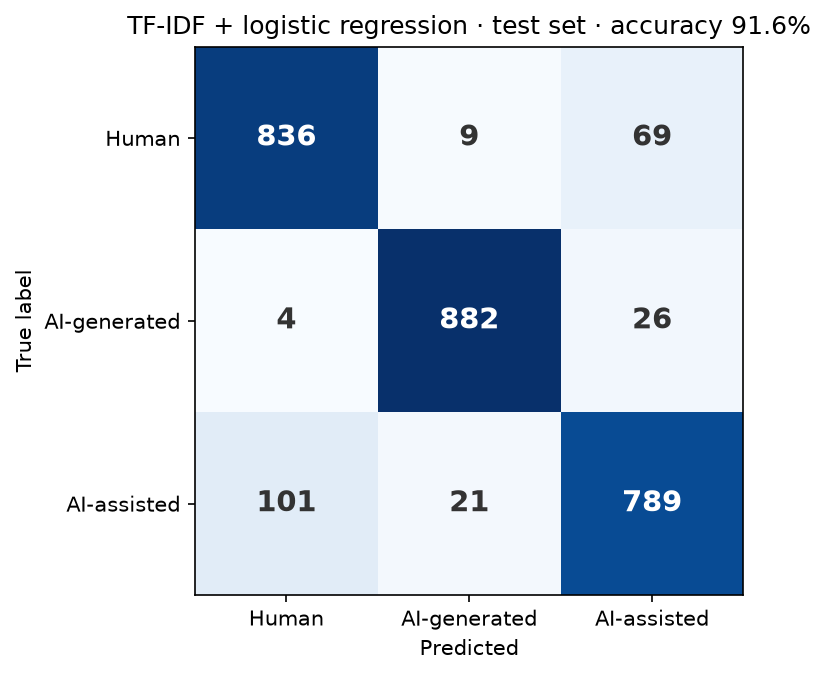

In [5]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1, 2])
pd.DataFrame(cm, index=[f"true {n}" for n in LABEL_NAMES],
             columns=[f"pred {n}" for n in LABEL_NAMES]).to_csv(RESULTS_DIR / "tfidf-confusion-matrix.csv")

fig, ax = plt.subplots(figsize=(5.2, 4.6), dpi=150)
ax.imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=14, fontweight="bold",
                color="white" if cm[i, j] > cm.max() / 2 else "#333")
ax.set_xticks([0, 1, 2], LABEL_NAMES)
ax.set_yticks([0, 1, 2], LABEL_NAMES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True label")
ax.set_title(f"TF-IDF + logistic regression · test set · accuracy {accuracy_score(y_test, test_pred):.1%}")
fig.patch.set_facecolor("white")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "tfidf-confusion-matrix.png", facecolor="white")
plt.show()

## Results by text length

In [6]:
df = pd.DataFrame({"true_label": y_test, "predicted_label": test_pred,
                   "word_count": dataset["test"]["word_count"]})
bins = [0, 70, 150, 300, 500, 750, np.inf]
names = ["≤70", "71–150", "151–300", "301–500", "501–750", "750+"]
df["length_bin"] = pd.cut(df["word_count"], bins=bins, labels=names)

by_length = df.groupby("length_bin", observed=True).apply(
    lambda part: pd.Series({
        "texts": len(part),
        "accuracy": (part["true_label"] == part["predicted_label"]).mean(),
        **{f"{name} error": (part.loc[part["true_label"] == label, "predicted_label"] != label).mean()
           for label, name in enumerate(LABEL_NAMES)},
    }),
    include_groups=False,
)
by_length.to_csv(RESULTS_DIR / "tfidf-by-length.csv")

shown = by_length.copy()
shown["texts"] = shown["texts"].astype(int)
for column in shown.columns[1:]:
    shown[column] = shown[column].map("{:.1%}".format)
print(shown.to_string())

            texts accuracy Human error AI-generated error AI-assisted error
length_bin                                                                 
≤70           399    77.7%       19.4%              11.9%             35.9%
71–150        293    91.8%        9.6%               1.6%             16.9%
151–300       640    93.1%        8.7%               2.9%             10.1%
301–500       342    94.7%        4.7%               2.2%              7.5%
501–750       653    94.9%        4.7%               1.0%              8.7%
750+          410    94.6%        6.4%               0.8%              8.6%


## Which words decide?

In [7]:
# Logistic regression is easy to look inside: each word or word pair gets one weight per class.
# These are the ones that push a text most strongly towards each class.
feature_names = vectorizer.get_feature_names_out()
top = {}
for label, name in enumerate(LABEL_NAMES):
    order = np.argsort(model.coef_[label])[::-1][:20]
    top[name] = [feature_names[i] for i in order]
top = pd.DataFrame(top)
top.to_csv(RESULTS_DIR / "tfidf-top-features.csv", index=False)
print(top.to_string())

           Human     AI-generated      AI-assisted
0           aber         zugleich           jedoch
1             so  institutionelle            sowie
2           hier           bleibt         zugleich
3            bzw        verbindet             etwa
4          schon        besonders   beispielsweise
5            von           solche         hingegen
6             es         sichtbar             dies
7           dann        ergänzend   darüber hinaus
8          haben             ihre  beziehungsweise
9         bisher          während          darüber
10         immer      bedingungen     insbesondere
11          auch             eine            zudem
12           hat     systematisch     anschließend
13          also     entscheidend           hinaus
14     aber auch           bildet        lediglich
15      und auch         entsteht            dabei
16         basis     nicht allein         mithilfe
17          sind        verfahren            darin
18  gleichzeitig            bli

## Try it on your own text

In [8]:
bundle = joblib.load(MODEL_DIR / "tfidf-logreg.joblib")

text = """Die vorliegende Arbeit untersucht, inwiefern digitale Lernplattformen die Motivation von
Studierenden beeinflussen. Dazu wurden Interviews mit zwölf Lehrenden geführt und ausgewertet."""

probs = bundle["model"].predict_proba(bundle["vectorizer"].transform([text]))[0]
for name, p in zip(bundle["labels"], probs):
    print(f"{name:13} {p:.1%}")

Human         42.1%
AI-generated  29.9%
AI-assisted   28.0%


## Upload to Hugging Face

Needs `HF_TOKEN` in `.env`. Set `UPLOAD = True` to run.

In [9]:
# Upload the model with a model card to the Hugging Face Hub. Starts private.
UPLOAD = True
HF_MODEL_REPO = "aliissa824/german-academic-ai-text-tfidf"
HF_DATASET_REPO = "aliissa824/german-academic-ai-text"

if UPLOAD:
    import os

    import sklearn
    from dotenv import load_dotenv
    from huggingface_hub import HfApi

    load_dotenv(REPO_ROOT / ".env", override=True)
    api = HfApi(token=os.environ["HF_TOKEN"])
    api.create_repo(HF_MODEL_REPO, repo_type="model", private=True, exist_ok=True)

    card = f"""---
language: de
license: cc-by-sa-4.0
library_name: sklearn
pipeline_tag: text-classification
datasets:
- {HF_DATASET_REPO}
---

# German academic AI-text detector · TF-IDF baseline

Classifies German academic text as **Human**, **AI-generated** or **AI-assisted** (human text polished by AI).
TF-IDF on {"words and word pairs" if best_ngram == (1, 2) else "single words"} + logistic regression (C={float(best["C"]):g}), trained on [{HF_DATASET_REPO}](https://huggingface.co/datasets/{HF_DATASET_REPO}).

| Test set ({len(y_test):,} texts) | |
|---|---|
| Accuracy | {accuracy_score(y_test, test_pred):.2%} |
| Macro-F1 | {f1_score(y_test, test_pred, average="macro"):.2%} |
| Human texts flagged as AI or AI-assisted | {is_ai_pred[~is_ai_true].mean():.2%} |

Labels: 0 = Human, 1 = AI-generated, 2 = AI-assisted. Short texts (≤70 words) are much less reliable.
The output is a probability, not proof that a text was or wasn't written with AI.

## Use

```python
import joblib
from huggingface_hub import hf_hub_download

bundle = joblib.load(hf_hub_download("{HF_MODEL_REPO}", "tfidf-logreg.joblib"))
probs = bundle["model"].predict_proba(bundle["vectorizer"].transform(["Ihr Text ..."]))[0]
print(dict(zip(bundle["labels"], probs.round(3))))
```

The file is a joblib (pickle) file: only load it from a source you trust. Saved with scikit-learn {sklearn.__version__}.
"""
    (MODEL_DIR / "README.md").write_text(card, encoding="utf-8")
    api.upload_folder(folder_path=str(MODEL_DIR), repo_id=HF_MODEL_REPO, repo_type="model")
    print(f"Uploaded: https://huggingface.co/{HF_MODEL_REPO}")

Uploaded: https://huggingface.co/aliissa824/german-academic-ai-text-tfidf
